# EuroSAT: MobileNetV2 transfer learning

Read [the project guide](README.md) before execution. Outputs below are historical, not rerun after portability edits. Source cell numbers in the guide are zero-based and correspond to `source-NNN` cell IDs. Training cells can be expensive.


In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns




In [2]:
TRAIN_DIR = r"training"
TEST_DIR  = r"testing"



In [11]:
IMG_SIZE = (128, 128)     # like CIFAR behavior
BATCH_SIZE = 64         # bigger batch = smoother curves

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_gen = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

val_gen = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

test_datagen = ImageDataGenerator(rescale=1./255)

test_gen = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

num_classes = len(train_gen.class_indices)
class_names = list(train_gen.class_indices.keys())

print("Classes:", class_names)

Found 17280 images belonging to 10 classes.
Found 4319 images belonging to 10 classes.
Found 5400 images belonging to 10 classes.
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [13]:
def build_transfer_model(base_model, num_classes):
    model = models.Sequential()
    model.add(base_model)
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dense(256, activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.3))
    model.add(layers.Dense(num_classes, activation='softmax'))
    return model

In [14]:
def compile_and_train(model, model_name):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),  # CIFAR LR
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=5,                # same as your second example
        batch_size=64
    )

    # ------------------------------
    # ACCURACY & LOSS PLOTS
    # ------------------------------
    plt.figure(figsize=(12,4))

    # Accuracy
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label='train accuracy')
    plt.plot(history.history['val_accuracy'], label='val accuracy')
    plt.title(f'{model_name} Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss
    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label='train loss')
    plt.plot(history.history['val_loss'], label='val loss')
    plt.title(f'{model_name} Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()

    # ------------------------------
    # PREDICTIONS
    # ------------------------------
    y_pred = np.argmax(model.predict(test_gen), axis=1)
    y_true = test_gen.classes

    # ------------------------------
    # CLASSIFICATION REPORT
    # ------------------------------
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # ------------------------------
    # CONFUSION MATRIX HEATMAP
    # ------------------------------
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(10,7))
    sns.heatmap(cm, annot=True, cmap="Blues", fmt="d",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

In [15]:
base_model = tf.keras.applications.MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(128, 128, 3)
)
base_model.trainable = False

model = build_transfer_model(base_model, num_classes)

Training MobileNetV2...


<local-eurosat>\tfenv\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
270/270 ━━━━━━━━━━━━━━━━━━━━ 318s 1s/step - accuracy: 0.7803 - loss: 0.6733 - val_accuracy: 0.8928 - val_loss: 0.3165
Epoch 2/5
270/270 ━━━━━━━━━━━━━━━━━━━━ 125s 463ms/step - accuracy: 0.8979 - loss: 0.2951 - val_accuracy: 0.9051 - val_loss: 0.2687
Epoch 3/5
270/270 ━━━━━━━━━━━━━━━━━━━━ 125s 463ms/step - accuracy: 0.9116 - loss: 0.2560 - val_accuracy: 0.9058 - val_loss: 0.2832
Epoch 4/5
270/270 ━━━━━━━━━━━━━━━━━━━━ 126s 465ms/step - accuracy: 0.9248 - loss: 0.2156 - val_accuracy: 0.9141 - val_loss: 0.2584
Epoch 5/5
270/270 ━━━━━━━━━━━━━━━━━━━━ 125s 461ms/step - accuracy: 0.9333 - loss: 0.1926 - val_accuracy: 0.9132 - val_loss: 0.2575


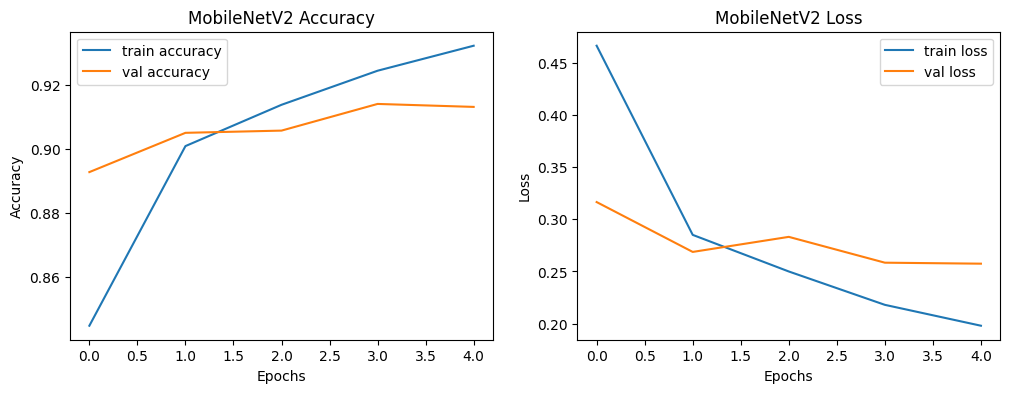

85/85 ━━━━━━━━━━━━━━━━━━━━ 35s 402ms/step

Classification Report:
                      precision    recall  f1-score   support

          AnnualCrop       0.85      0.94      0.89       600
              Forest       0.95      0.95      0.95       600
HerbaceousVegetation       0.81      0.90      0.85       600
             Highway       0.87      0.82      0.84       500
          Industrial       0.98      0.93      0.95       500
             Pasture       0.93      0.77      0.84       400
       PermanentCrop       0.85      0.84      0.84       500
         Residential       0.98      0.96      0.97       600
               River       0.87      0.87      0.87       500
             SeaLake       0.97      0.99      0.98       600

            accuracy                           0.90      5400
           macro avg       0.91      0.90      0.90      5400
        weighted avg       0.91      0.90      0.90      5400



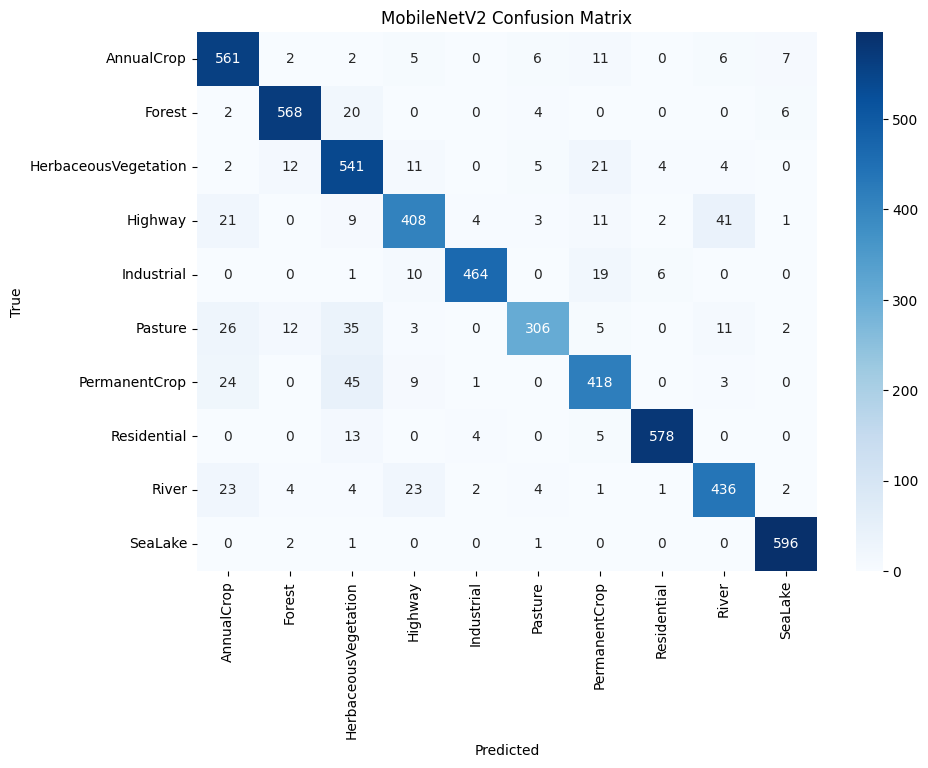

In [16]:
print("Training MobileNetV2...")
compile_and_train(model, "MobileNetV2")

In [1]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
train_dir = "training"
test_dir = "testing"

img_size = (128, 128)
batch_size = 32

datagen = ImageDataGenerator(
    rescale=1/255.,
    validation_split=0.2   # 20% validation
)

train = datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    subset="training"
)

val = datagen.flow_from_directory(
    train_dir,   # still from training folder
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    subset="validation"
)

test = ImageDataGenerator(rescale=1/255.).flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=1,
    shuffle=False,
    class_mode="categorical"
)

class_names = list(train.class_indices.keys())
num_classes = len(class_names)

print("Classes:", class_names)



Found 17280 images belonging to 10 classes.
Found 4319 images belonging to 10 classes.
Found 5400 images belonging to 10 classes.
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [4]:
def build_transfer_model(base_model, num_classes):
    model = Sequential()
    model.add(base_model)
    model.add(GlobalAveragePooling2D())
    model.add(Dense(256, activation='relu'))
    model.add(BatchNormalization())
    model.add(Dropout(0.3))
    model.add(Dense(num_classes, activation='softmax'))
    return model


In [5]:
base_model = tf.keras.applications.MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(128, 128, 3)
)

# Fine-tune آخر 20 طبقة
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False


In [6]:
model = build_transfer_model(base_model, num_classes)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │

 Total params: 2,589,514 (9.88 MB)


 Trainable params: 1,537,098 (5.86 MB)


 Non-trainable params: 1,052,416 (4.01 MB)


In [7]:
history = model.fit(
    train,
    validation_data=val,
    epochs=10,
    batch_size=32
)


<local-eurosat>\tfenv\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 308s 556ms/step - accuracy: 0.4153 - loss: 1.9581 - val_accuracy: 0.4709 - val_loss: 1.8213
Epoch 2/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 144s 266ms/step - accuracy: 0.7566 - loss: 0.7375 - val_accuracy: 0.7444 - val_loss: 0.7804
Epoch 3/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 148s 275ms/step - accuracy: 0.8148 - loss: 0.5543 - val_accuracy: 0.8483 - val_loss: 0.4610
Epoch 4/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 148s 274ms/step - accuracy: 0.8506 - loss: 0.4521 - val_accuracy: 0.8782 - val_loss: 0.3614
Epoch 5/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 144s 266ms/step - accuracy: 0.8725 - loss: 0.3732 - val_accuracy: 0.8928 - val_loss: 0.3217
Epoch 6/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 142s 264ms/step - accuracy: 0.8949 - loss: 0.3203 - val_accuracy: 0.8995 - val_loss: 0.2955
Epoch 7/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 143s 264ms/step - accuracy: 0.9044 - loss: 0.2873 - val_accuracy: 0.9062 - val_loss: 0.2781
Epoch 8/10
540/540 ━━━━━━━━━━━━━━━━━━━━ 143s 264ms/step - accuracy: 0.9144 -

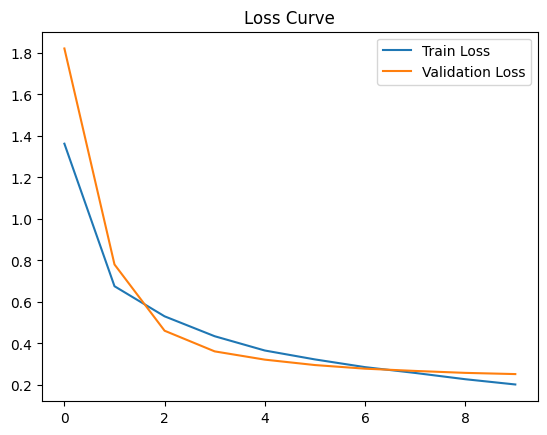

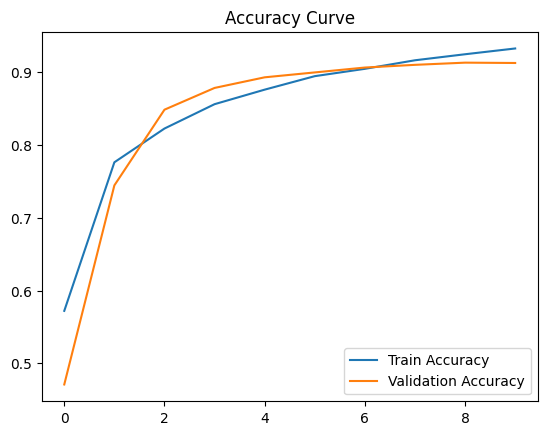

In [8]:
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.title("Loss Curve")
plt.show()

plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.title("Accuracy Curve")
plt.show()


5400/5400 ━━━━━━━━━━━━━━━━━━━━ 76s 14ms/step


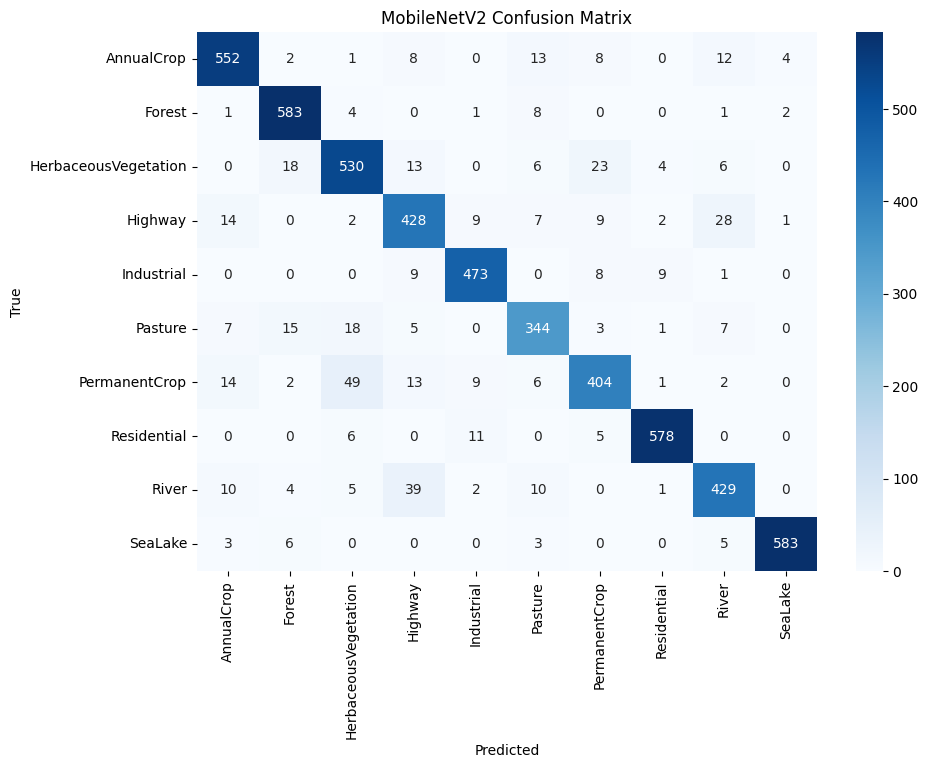

                      precision    recall  f1-score   support

          AnnualCrop       0.92      0.92      0.92       600
              Forest       0.93      0.97      0.95       600
HerbaceousVegetation       0.86      0.88      0.87       600
             Highway       0.83      0.86      0.84       500
          Industrial       0.94      0.95      0.94       500
             Pasture       0.87      0.86      0.86       400
       PermanentCrop       0.88      0.81      0.84       500
         Residential       0.97      0.96      0.97       600
               River       0.87      0.86      0.87       500
             SeaLake       0.99      0.97      0.98       600

            accuracy                           0.91      5400
           macro avg       0.90      0.90      0.90      5400
        weighted avg       0.91      0.91      0.91      5400



In [9]:
y_true = test.classes
y_pred = np.argmax(model.predict(test), axis=1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10,7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("MobileNetV2 Confusion Matrix")
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))


model.save_weights("mobilenet_best_weights.weights.h5")